# R-MaRS — bản demo đầu-cuối (SMOKE)
Ordinary vs KL-block-DRO **marginal-value feedback** cho GP tìm factor, VN100.
Một notebook, ít code, dựa trên `pandas / cvxpy / sklearn / numpy`. GP là bản tối giản tự viết (DEAP chưa cài).

**Pipeline:** config → load + audit → tiền xử lý không trạng thái → split walk-forward → Model 2 (DRO) → Model 1 (GP) → train 2 arm → đánh giá + 2 chart.
`SMOKE=True` chỉ chạy vài origin với ngân sách nhỏ để kiểm tra pipeline, **không dùng để kết luận H1**.

In [1]:
import time, random, functools, warnings
from pathlib import Path
import numpy as np, pandas as pd, cvxpy as cp, matplotlib.pyplot as plt
from cvxpy.constraints import ExpCone
from scipy.optimize import minimize_scalar
from sklearn.covariance import LedoitWolf
warnings.filterwarnings("ignore")

# Tham số "đăng ký trước". fee/kappa/nav/chi CHƯA hiệu chỉnh. SMOKE dùng fee=0.1%/chiều (lạc quan) vì ở 0.3%/chiều mọi sleeve có lợi suất ròng âm -> optimizer giữ 100% tiền mặt.
CFG = dict(SMOKE=True, gamma=3.0, rho=0.05, fee=0.001, kappa=0.02, nav=1e9, chi=0.1,
           horizon=5, top=0.10, max_abs_ret=0.4,
           pool_max=3, pop=12, gens=3, max_nodes=15, inner_folds=4, boot=300, n_origins=2, seeds=[0])
if not CFG["SMOKE"]:
    CFG.update(pool_max=8, pop=60, gens=15, inner_folds=12, n_origins=99, seeds=[0, 1, 2, 3, 4])
G, RHO, H = CFG["gamma"], CFG["rho"], CFG["horizon"]
DATA = Path("data/selected")

## 1. Load + audit (data gates)

In [2]:
px = pd.read_csv(DATA/"ohlcv.csv", parse_dates=["Date"]); px["Date"] = px.Date.dt.tz_localize(None)
cons = pd.read_csv(DATA/"constituents.csv")
lj = pd.read_excel(DATA/"vn100_leavers_joiners.xlsx", header=None, skiprows=4,
                   names=["Status", "Issuer", "Code", "Date"])
vn100 = pd.read_excel(DATA/"vn100_index.xlsx", skiprows=29,
                      usecols=["Exchange Date", "Open", "Close"]).set_index("Exchange Date").sort_index()

# foreign-flow: kiểm tra ngày bên trong file có khớp tên file không (mẫu 1/60 file)
fl = sorted((Path("data/full/Giaodich_Khoingoai")).glob("*.xls"))[::60]
inner = lambda f: str(pd.read_excel(f, header=None, usecols=[2], skiprows=9, nrows=1).iat[0, 0])[:10]
fl_ok = np.mean([inner(f) == f.stem[-10:] for f in fl])

ret_ = px.pivot(index="Date", columns="Ticker", values="Close").pct_change(fill_method=None)
audit = pd.Series({
    "ohlcv rows / tickers / dates": f"{len(px):,} / {px.Ticker.nunique()} / {px.Date.nunique()}",
    "range": f"{px.Date.min():%Y-%m-%d} .. {px.Date.max():%Y-%m-%d}",
    "duplicate (Date,Ticker)": int(px.duplicated(["Date", "Ticker"]).sum()),
    "zero-volume rows": f"{(px.Volume == 0).mean():.1%}",
    "invalid OHLC rows": int(((px.High < px.Low) | (px.Close > px.High + 1e-9) | (px.Close < px.Low - 1e-9)).sum()),
    "|daily ret| > max_abs_ret (nghi corporate action chưa điều chỉnh)": int((ret_.abs() > CFG["max_abs_ret"]).sum().sum()),
    "constituent tickers missing in ohlcv": len(set(cons.ticker) - set(px.Ticker)),
    "leavers/joiners events (file nói từ 2014)": f"{len(lj)} rows, {lj.Date.min():%Y-%m-%d}..{lj.Date.max():%Y-%m-%d}, {lj.Date.nunique()} ngày",
    "VN100 index (benchmark)": f"{vn100.index.min():%Y-%m-%d}..{vn100.index.max():%Y-%m-%d}",
    "foreign-flow: tỷ lệ file có ngày trong file == tên file (mẫu)": f"{fl_ok:.0%}",
})
audit.to_frame("value")

,value
ohlcv rows / tickers / dates,"475,679 / 222 / 2282"
range,2017-01-03 .. 2026-02-25
"duplicate (Date,Ticker)",0
zero-volume rows,3.9%
invalid OHLC rows,195
|daily ret| > max_abs_ret (nghi corporate action chưa điều chỉnh),34
constituent tickers missing in ohlcv,3
leavers/joiners events (file nói từ 2014),"114 rows, 2025-03-28..2026-08-03, 8 ngày"
VN100 index (benchmark),2009-01-02..2026-10-30
foreign-flow: tỷ lệ file có ngày trong file == tên file (mẫu),7%


**Quyết định từ audit** (fail-closed):
- Giá/volume: dùng `VN100/ohlcv.csv` (222 mã, gồm mã đã hủy niêm yết). `full/VN100_EOD.xlsx` **không dùng**: chỉ 111 mã hiện hành (survivorship) và thang volume không khớp.
- Thành viên rổ: `constituents.csv` theo quý, **trễ 1 quý** để tránh look-ahead. File leavers/joiners chỉ phủ 8 ngày nên không đủ dựng lại lịch sử.
- `VN100 index` từ `full/` dùng làm benchmark.
- Foreign-flow, macro, bond, fx, derivatives: **loại** (chưa có release timestamp; foreign-flow phần lớn file là bản chụp ngày tải, không phải ngày trong tên file).

## 2. Tiền xử lý không trạng thái

In [3]:
O, Hi, L, C, V = (px.pivot(index="Date", columns="Ticker", values=c) for c in ["Open", "High", "Low", "Close", "Volume"])
ret = C.pct_change(fill_method=None)
adv = (C * 1e3 * V).rolling(20, min_periods=15).mean().shift(1)            # ADV20 (VND), trễ 1 phiên
sig = np.arange(0, len(C) - H, H)                                           # tín hiệu cuối phiên s, vào open s+1, ra close s+H
ep = pd.DataFrame({"sig": C.index[sig], "ex": C.index[sig + H]})            # lịch episode không chồng lấn

# nhãn: open(s+1) -> close(s+H). Delisting: dùng giá cuối cùng (ffill). ponytail: chưa có delisting proceeds; chặn lệnh = 0 return.
Rfull = C.ffill().shift(-H) / O.shift(-1) - 1
jump = ret.abs().gt(CFG["max_abs_ret"]).astype(float).rolling(H).max().shift(-H) > 0   # cửa sổ chứa nhảy giá bất thường
Rs = Rfull.mask(jump).iloc[sig]

member = pd.crosstab(pd.PeriodIndex(cons.quarter, freq="Q"), cons.ticker).astype(bool)
M = member.reindex(C.index.to_period("Q") - 1).reindex(columns=C.columns).fillna(False).astype(bool).set_axis(C.index)
adv_min = CFG["nav"] / (CFG["chi"] * 5)                                     # ponytail: giả định sleeve >=5 mã để tôn trọng participation cap
E = (M & (adv >= adv_min) & C.notna()).iloc[sig]                            # universe tại thời điểm tín hiệu (không dùng nhãn)
sqrtNADV = np.sqrt(CFG["nav"] / adv).iloc[sig].fillna(0)
print(f"{len(ep)} episodes | eligible/episode: median {E.sum(1).median():.0f}, min {E.sum(1).min()} | masked jump windows: {int(jump.iloc[sig].sum().sum())}")

456 episodes | eligible/episode: median 91, min 0 | masked jump windows: 34


## 3. Split walk-forward (nested)
Outer origin mỗi 6 tháng (đầu tiên ≥ 42 tháng sau dữ liệu đầu). Mỗi origin: `D` (search feedback, các fold OOF theo quý, A_k mở rộng) → `I` (3 tháng cuối, chọn checkpoint, GP không thấy) → `test` (6 tháng, khóa). Episode nào có nhãn chồng sang đoạn sau đều bị loại (purge).

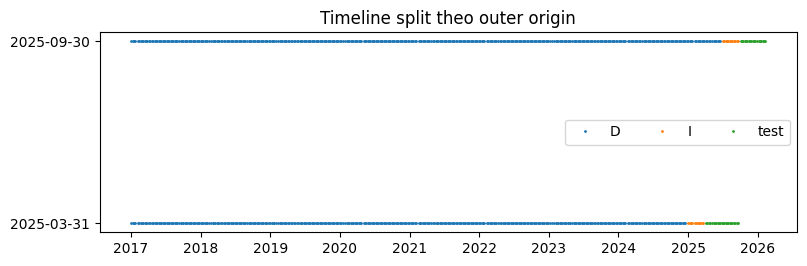

In [4]:
def splits(T):
    cut = T - pd.DateOffset(months=3)
    D = np.flatnonzero(ep.ex <= cut)
    I = np.flatnonzero((ep.sig > cut) & (ep.ex <= T))
    train = np.flatnonzero(ep.ex <= T)
    test = np.flatnonzero((ep.sig > T) & (ep.ex <= T + pd.DateOffset(months=6)))
    ps = [p for p in pd.period_range(C.index[0] + pd.DateOffset(years=3), cut, freq="Q") if p.end_time <= cut]
    folds = []
    for p in ps:
        Vk = D[(ep.sig[D] >= p.start_time) & (ep.ex[D] <= p.end_time)]
        Ak = D[ep.ex[D] < ep.sig[Vk[0]]] if len(Vk) else []
        if len(Vk) >= 5 and len(Ak) >= 30: folds.append((Ak, Vk))
    return dict(T=T, D=D, I=I, train=train, test=test, folds=folds[-CFG["inner_folds"]:])

grid = pd.date_range("2020-09-30", C.index[-1], freq="6ME")
origins = [C.index[C.index <= d][-1] for d in grid]
origins = [T for T in origins if len(splits(T)["test"]) >= 10 and splits(T)["folds"]][-CFG["n_origins"]:]

fig, ax = plt.subplots(figsize=(9, 1.6 + 0.5 * len(origins)))
for i, T in enumerate(origins):
    s = splits(T)
    for name, idx, col in [("D", s["D"], "tab:blue"), ("I", s["I"], "tab:orange"), ("test", s["test"], "tab:green")]:
        ax.plot(ep.sig[idx], [i] * len(idx), ".", ms=2, color=col, label=name if i == 0 else None)
ax.set_yticks(range(len(origins))); ax.set_yticklabels([f"{T:%Y-%m-%d}" for T in origins]); ax.legend(ncol=3); ax.set_title("Timeline split theo outer origin")
plt.show()

## 4. Model 2: tối ưu danh mục (empirical `O` / KL-block-DRO `R`)
Mỗi sleeve `j` có lợi suất ròng tuyến tính `a_jb` và hệ số impact `k_jb`; lợi suất ròng của `w` là `A@w − K@w^1.5` (lõm). KL-DRO giải bằng **dạng đối ngẫu** (exponential cone) nên là bài toán lồi, không cần khởi tạo.

In [5]:
@functools.cache
def sleeve(t):
    """top-decile equal-weight sleeve -> (a: net linear return, k: impact coef, Hh: membership)."""
    F = ev(t).replace([np.inf, -np.inf], np.nan).iloc[sig].where(E)
    Hh = F.rank(axis=1, pct=True) > 1 - CFG["top"]
    Hw = Hh.div(Hh.sum(1).replace(0, np.nan), axis=0).fillna(0)
    x = (Hw * Rs.fillna(0)).sum(1).to_numpy()                               # gross; cash nếu không có mã
    inv = Hh.any(axis=1).to_numpy()
    a = x - CFG["fee"] * (2 + x) * inv                                      # phí tỷ lệ cả mua và bán (bán trên giá trị đã đổi)
    k = 2 * CFG["kappa"] * (Hw ** 1.5 * sqrtNADV).sum(1).to_numpy()         # impact k*n*sqrt(n*N/ADV), mua+bán. ponytail: tách theo sleeve, bỏ qua overlap giữa sleeve
    return a, k, Hh

def mats(pool, idx):
    if not pool: return np.zeros((len(idx), 0)), np.zeros((len(idx), 0))
    return (np.column_stack([sleeve(t)[0][idx] for t in pool]), np.column_stack([sleeve(t)[1][idx] for t in pool]))

net = lambda A, Kp, w: A @ w - Kp @ np.abs(w) ** 1.5                        # lợi suất ròng mỗi episode
U = lambda r: r.mean() - G / 2 * r.var(ddof=1)                              # certainty equivalent
Ub = lambda R: R.mean(1) - G / 2 * R.var(1, ddof=1)                         # CE theo từng bootstrap sample

def solve(A, Kp, mode):
    n, K = A.shape
    if K == 0: return np.zeros(0)
    S = LedoitWolf().fit(A).covariance_                                     # covariance co rút, chỉ từ train, KHÔNG robust theo q
    w, z = cp.Variable(K, nonneg=True), cp.Variable(K, nonneg=True)
    ell = -100 * A @ w + 100 * Kp @ z                                       # block loss (đơn vị %)
    quad = 100 * G / 2 * cp.quad_form(w, cp.psd_wrap(S))
    con = [cp.sum(w) <= 1, cp.power(w, 1.5) <= z]                           # phần còn lại = tiền mặt. ponytail: phí mua chưa trừ vào cash
    if mode == "O":
        obj = -cp.sum(ell) / n - quad
    else:                                                                   # max_q E_q[loss] = min_lam lam*rho + lam*log E_p exp(loss/lam)
        m, lam, y = cp.Variable(), cp.Variable(nonneg=True), cp.Variable(n)
        con += [ExpCone(ell - m, lam * np.ones(n), y), cp.sum(y) / n <= lam]
        obj = -(m + lam * RHO) - quad
    try: cp.Problem(cp.Maximize(obj), con).solve(solver=cp.CLARABEL)
    except cp.SolverError: pass
    return np.clip(w.value, 0, None) if w.value is not None else np.zeros(K)

# self-check: nghiệm cvxpy (mode R, 1 sleeve, không impact) == grid-search brute-force dùng dạng đối ngẫu 1-D
a = np.random.default_rng(0).normal(0.007, 0.03, (60, 1)); s2 = LedoitWolf().fit(a).covariance_[0, 0]
def worst_mean(r):
    f = lambda ll: np.exp(ll) * RHO + np.exp(ll) * np.log(np.mean(np.exp(-r / np.exp(ll))))
    return -minimize_scalar(f, bounds=(-9, 3), method="bounded").fun
ws = np.linspace(0, 1, 201); w_grid = ws[np.argmax([worst_mean(a[:, 0] * w) - G / 2 * w ** 2 * s2 for w in ws])]
w_cvx = solve(a, np.zeros_like(a), "R")[0]
print(f"self-check: w_cvxpy={w_cvx:.3f}  w_bruteforce={w_grid:.3f}"); assert 0.05 < w_grid < 0.95 and abs(w_cvx - w_grid) < 0.03

self-check: w_cvxpy=0.366  w_bruteforce=0.365


## 5. Model 1: GP (typed → gộp thành 1 kiểu panel; thêm typing khi grammar lớn)
Cây biểu thức trên panel `date × ticker`; MAP-Elites theo (RankIC, turnover); fitness = **LCB 5% của giá trị biên OOF ghép cặp** `Δ(f|S)` (bootstrap khối, cùng khối cho `S` và `S∪{f}`).
Đột biến subtree thay cho crossover (ponytail: thêm crossover/DEAP khi cần).

In [6]:
TS = dict(ts_mean=lambda x, d: x.rolling(d, min_periods=d // 2).mean(),
          ts_std=lambda x, d: x.rolling(d, min_periods=d // 2).std(),
          ts_delta=lambda x, d: x - x.shift(d))
UN = dict(cs_rank=lambda x: x.rank(axis=1, pct=True), neg=lambda x: -x)
BI = dict(add=lambda a, b: a + b, sub=lambda a, b: a - b, mul=lambda a, b: a * b, div=lambda a, b: a / b.where(b != 0))
TERM = dict(close=C, open=O, high=Hi, low=L, volume=V, ret=ret); WIN = (5, 10, 20, 60)

def rand_tree(r, d):
    if d == 0 or r.random() < 0.3: return r.choice(list(TERM))
    k = r.choice(["ts", "un", "bi"])
    if k == "ts": return (r.choice(list(TS)), rand_tree(r, d - 1), r.choice(WIN))
    if k == "un": return (r.choice(list(UN)), rand_tree(r, d - 1))
    return (r.choice(list(BI)), rand_tree(r, d - 1), rand_tree(r, d - 1))

size = lambda t: 1 if isinstance(t, str) else 1 + sum(size(c) for c in t[1:] if not isinstance(c, int))

def mutate(r, t):
    if isinstance(t, str) or r.random() < 0.25: new = rand_tree(r, 2)
    else:
        i = r.randrange(1, len(t))
        new = t[:i] + ((r.choice(WIN),) if isinstance(t[i], int) else (mutate(r, t[i]),)) + t[i + 1:]
    return new if size(new) <= CFG["max_nodes"] else t

@functools.lru_cache(maxsize=200)
def ev(t):
    if isinstance(t, str): return TERM[t]
    op, *a = t
    if op in TS: return TS[op](ev(a[0]), a[1])
    return (UN.get(op) or BI[op])(*map(ev, a))

def descr(t, idx):                                                          # descriptor chỉ từ dữ liệu train
    F = ev(t).replace([np.inf, -np.inf], np.nan).iloc[sig].where(E).iloc[idx]
    ic = F.rank(axis=1).corrwith(Rs.where(E).iloc[idx].rank(axis=1), axis=1).mean()
    Hh = sleeve(t)[2].iloc[idx]
    to = ((Hh & ~Hh.shift(1, fill_value=False)).sum(1) / Hh.sum(1).replace(0, np.nan)).mean()
    return ic, to

def block_idx(n, B):                                                        # moving-block bootstrap, chung cho mọi ứng viên
    Lb = max(2, round(n ** (1 / 3))); nb = -(-n // Lb)
    st = np.random.default_rng(123).integers(0, n - Lb + 1, (B, nb))
    return (st[:, :, None] + np.arange(Lb)).reshape(B, -1)[:, :n]

class Ctx:                                                                  # cache nghiệm Model 2 theo (pool, fold)
    def __init__(s, folds, mode): s.folds, s.mode, s.cache, s.solves = folds, mode, {}, 0
    def w(s, pool, k):
        if (pool, k) not in s.cache:
            s.cache[pool, k] = solve(*mats(pool, s.folds[k][0]), s.mode); s.solves += 1
        return s.cache[pool, k]

def fitness(f, pool, ctx):
    S2, dk, nk, r0, r1 = pool + (f,), [], [], [], []
    for k, (_, Vk) in enumerate(ctx.folds):
        a = net(*mats(pool, Vk), ctx.w(pool, k)); b = net(*mats(S2, Vk), ctx.w(S2, k))
        dk.append(U(b) - U(a)); nk.append(len(Vk)); r0.append(a); r1.append(b)
    r0, r1 = np.concatenate(r0), np.concatenate(r1); ix = block_idx(len(r0), CFG["boot"])
    return np.average(dk, weights=nk), np.quantile(Ub(r1[ix]) - Ub(r0[ix]), 0.05)   # (Δ̂ chuẩn OOF, LCB làm fitness)

def gp_search(ctx, D, seed):
    pool, ckpts, hist, dc = (), [], [], {}
    d0 = np.array([descr(t, D) for t in dict.fromkeys(rand_tree(random.Random(seed * 7 + i), 3) for i in range(CFG["pop"]))])
    edges = np.nanquantile(d0, [1 / 3, 2 / 3], axis=0)                      # bin edges cố định theo origin, chỉ từ train
    cell = lambda t: tuple(int(np.searchsorted(edges[:, j], v)) for j, v in enumerate(dc.setdefault(t, descr(t, D))))
    for step in range(CFG["pool_max"]):
        r = random.Random(seed * 1000 + step)                               # cùng seed => cùng quần thể ban đầu ở cả 2 arm
        P, arch = [rand_tree(r, 3) for _ in range(CFG["pop"])], {}
        for g in range(CFG["gens"]):
            for t in dict.fromkeys(P):
                if t in pool or sleeve(t)[2].any(axis=1).mean() < 0.5: continue   # bỏ factor hằng/gần rỗng
                dl, lcb = fitness(t, pool, ctx); c = cell(t)
                if c not in arch or (lcb, -size(t)) > (arch[c][0], -size(arch[c][1])): arch[c] = (lcb, t, dl)
            hist.append(dict(step=step, g=g, best=max(v[0] for v in arch.values()), med=np.median([v[0] for v in arch.values()])))
            P = [mutate(r, r.choice([v[1] for v in arch.values()])) for _ in range(CFG["pop"])]
        pool += (max(arch.values(), key=lambda v: (v[0], -size(v[1])))[1],); ckpts.append(pool)   # luôn thêm, kể cả LCB<=0
    return ckpts, hist

## 6. Huấn luyện: 2 arm × origin × seed
Mỗi arm (`O`, `R`) chỉ khác **optimizer dùng trong feedback**. Sau search: chọn checkpoint trên `I` (1 lần), refit trên toàn bộ train với **cả hai** optimizer cuối → 4 ô `OO, OR, RO, RR` (ma trận 2×2 gần như miễn phí, vì chỉ thêm 2 lần fit cuối, không thêm search). Primary: `RR − OR`.

In [7]:
def run_origin(T, seed):
    s = splits(T); out = dict(seed=seed, T=T, dates=ep.sig[s["test"]].values, ret={}, hist={}, pool={}, sec={}, solves={})
    for arm in "OR":
        t0 = time.time(); ctx = Ctx(s["folds"], arm)
        ckpts, out["hist"][arm] = gp_search(ctx, s["D"], seed)
        pick = ckpts[int(np.argmax([U(net(*mats(p, s["I"]), solve(*mats(p, s["D"]), "R"))) for p in ckpts]))]   # 1 lần trên I
        for fin in "OR":
            out["ret"][arm + fin] = net(*mats(pick, s["test"]), solve(*mats(pick, s["train"]), fin))
        out["pool"][arm], out["sec"][arm], out["solves"][arm] = [str(t) for t in pick], time.time() - t0, ctx.solves
    return out

OUT = []
for seed in CFG["seeds"]:
    for T in origins:
        OUT.append(run_origin(T, seed)); o = OUT[-1]
        print(f"seed {seed} origin {T:%Y-%m-%d}: sec O/R = {o['sec']['O']:.0f}/{o['sec']['R']:.0f} | solves O/R = {o['solves']['O']}/{o['solves']['R']} | |pool| O/R = {len(o['pool']['O'])}/{len(o['pool']['R'])}")

seed 0 origin 2025-03-31: sec O/R = 9/11 | solves O/R = 372/340 | |pool| O/R = 1/1


seed 0 origin 2025-09-30: sec O/R = 8/12 | solves O/R = 380/380 | |pool| O/R = 2/3


## 7. Đánh giá

In [8]:
vn_ret = (vn100.Close.reindex(C.index).shift(-H) / vn100.Open.reindex(C.index).shift(-1) - 1).iloc[sig].set_axis(ep.sig)   # ponytail: benchmark không phí

def assemble(seed):
    rs = [o for o in OUT if o["seed"] == seed]; dt = np.concatenate([o["dates"] for o in rs])
    R = pd.DataFrame({c: np.concatenate([o["ret"][c] for o in rs]) for c in ["OO", "OR", "RO", "RR"]}, index=dt)
    ew = Rs.where(E).mean(1).set_axis(ep.sig).reindex(dt).fillna(0)
    R["EW"] = ew - CFG["fee"] * (2 + ew)                                   # chia đều universe, cùng cấu trúc phí tỷ lệ
    R["VN100"] = vn_ret.reindex(dt).fillna(0)
    return R

def metrics(r):
    cum = (1 + r).cumprod()
    return pd.Series(dict(mean=r.mean(), CE=U(r.to_numpy()), sharpe=r.mean() / r.std() * np.sqrt(252 / H),
                          total=cum.iloc[-1] - 1, mdd=(cum / cum.cummax() - 1).min(), n=len(r)))

RES = {sd: assemble(sd) for sd in CFG["seeds"]}
tab = pd.concat({sd: R.apply(metrics).T for sd, R in RES.items()}, names=["seed", "arm"])
display(tab.round(4))

for sd, R in RES.items():
    ix = block_idx(len(R), 2000); d = Ub(R.RR.to_numpy()[ix]) - Ub(R.OR.to_numpy()[ix])
    ce = {c: U(R[c].to_numpy()) for c in ["OO", "OR", "RO", "RR"]}
    print(f"seed {sd}: ΔCE(RR−OR) = {ce['RR'] - ce['OR']:+.5f} | bootstrap 5%..95% = [{np.quantile(d, .05):+.5f}, {np.quantile(d, .95):+.5f}] "
          f"| feedback main effect = {(ce['RO'] + ce['RR'] - ce['OO'] - ce['OR']) / 2:+.5f} | interaction = {(ce['RR'] - ce['OR']) - (ce['RO'] - ce['OO']):+.5f}")

mean      CE  sharpe   total     mdd     n
seed arm                                                
0    OO     0.0000  0.0000  0.2032  0.0000 -0.0000  43.0
     OR     0.0000  0.0000  0.3292  0.0000 -0.0000  43.0
     RO     0.0000  0.0000  1.3178  0.0000 -0.0000  43.0
     RR     0.0000  0.0000  1.9085  0.0000 -0.0000  43.0
     EW     0.0040  0.0031  1.1505  0.1708 -0.1283  43.0
     VN100  0.0106  0.0095  2.7660  0.5494 -0.0918  43.0

seed 0: ΔCE(RR−OR) = +0.00000 | bootstrap 5%..95% = [-0.00000, +0.00000] | feedback main effect = +0.00000 | interaction = -0.00000


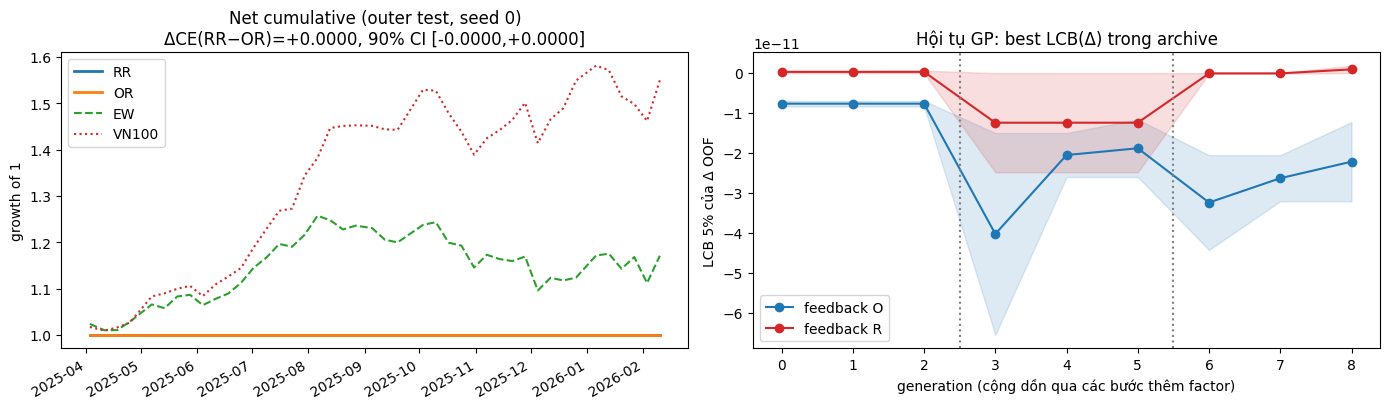

{'O': ["('ts_mean', 'high', 5)", "('ts_std', 'volume', 10)"], 'R': ["('ts_mean', ('div', ('mul', 'volume', 'open'), ('div', 'volume', ('cs_rank', 'volume'))), 60)", 'high', "('sub', ('ts_delta', ('div', 'open', 'high'), 60), ('cs_rank', ('neg', 'ret')))"]}


In [9]:
R0 = RES[CFG["seeds"][0]]; ce = {c: U(R0[c].to_numpy()) for c in R0}
ix = block_idx(len(R0), 2000); d = Ub(R0.RR.to_numpy()[ix]) - Ub(R0.OR.to_numpy()[ix])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))

# Chart 1: lợi suất ròng tích lũy trên các outer test block (gộp theo thời gian)
for c, kw in [("RR", dict(lw=2)), ("OR", dict(lw=2)), ("EW", dict(ls="--")), ("VN100", dict(ls=":"))]:
    (1 + R0[c]).cumprod().plot(ax=ax[0], label=c, **kw)
ax[0].set(title=f"Net cumulative (outer test, seed {CFG['seeds'][0]})\nΔCE(RR−OR)={ce['RR'] - ce['OR']:+.4f}, 90% CI [{np.quantile(d, .05):+.4f},{np.quantile(d, .95):+.4f}]", ylabel="growth of 1")
ax[0].legend()

# Chart 2: hội tụ GP — best LCB theo thế hệ (trung bình các run, dải min-max); vạch dọc = thêm factor vào pool (context mới)
for arm, col in [("O", "tab:blue"), ("R", "tab:red")]:
    B = np.array([[h["best"] for h in o["hist"][arm]] for o in OUT])
    x = np.arange(B.shape[1]); ax[1].plot(x, B.mean(0), color=col, marker="o", label=f"feedback {arm}")
    ax[1].fill_between(x, B.min(0), B.max(0), color=col, alpha=.15)
for s_ in range(1, CFG["pool_max"]): ax[1].axvline(s_ * CFG["gens"] - .5, color="gray", ls=":")
ax[1].set(title="Hội tụ GP: best LCB(Δ) trong archive", xlabel="generation (cộng dồn qua các bước thêm factor)", ylabel="LCB 5% của Δ OOF"); ax[1].legend()
plt.tight_layout(); plt.show()
print({arm: [o["pool"][arm] for o in OUT][-1] for arm in "OR"})

## Giới hạn của bản SMOKE (đọc trước khi diễn giải)
- Ít origin, ngân sách GP nhỏ, 1 seed ⇒ khoảng tin cậy rất rộng; chỉ dùng để kiểm tra pipeline chạy đúng, không phải bằng chứng cho H1.
- `fee/kappa/nav/chi` chưa hiệu chỉnh; chưa mô hình hóa biên độ giá, T+2, lệnh không khớp (volume = 0 ở phiên vào lệnh), delisting proceeds.
- Tìm kiếm GP là thích ứng trên `D`: LCB không phải khoảng tin cậy hậu kiểm; chỉ outer test là kết quả.
- Chưa có CVaR comparator, baseline γ-tuned cho arm `O` (rủi ro: `R` chỉ tương đương tăng γ), power analysis.